In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Ready for Tourism Data Analysis project!")

All libraries imported successfully!
Ready for Tourism Data Analysis project!


In [5]:
import os

project_name = "Tourism_Data_Analysis"

folders = [
    "dataset",
    "notebook",
    "visualizations",
    "dashboard",
    "report"
]

for folder in folders:
    os.makedirs(
        os.path.join(project_name, folder),
        exist_ok=True
    )

print("Project folders created successfully!")

for folder in folders:
    print(folder)

Project folders created successfully!
dataset
notebook
visualizations
dashboard
report


In [6]:
import numpy as np
import pandas as pd
import os

np.random.seed(42)

destinations = {
    "India": ["Chennai", "Goa", "Jaipur", "Kerala", "Agra"],
    "France": ["Paris", "Nice", "Lyon"],
    "Italy": ["Rome", "Venice", "Milan"],
    "Japan": ["Tokyo", "Kyoto", "Osaka"],
    "Thailand": ["Bangkok", "Phuket", "Chiang Mai"],
    "USA": ["New York", "Los Angeles", "Las Vegas"]
}

countries = list(destinations.keys())

n = 600

country_data = np.random.choice(countries, size=n)

destination_data = [
    np.random.choice(destinations[country])
    for country in country_data
]

travel_dates = pd.to_datetime(
    np.random.choice(
        pd.date_range("2025-01-01", "2025-12-31"),
        size=n
    )
)

df = pd.DataFrame({
    "Travel_Date": travel_dates,
    "Country": country_data,
    "Destination": destination_data,
    "Visitors": np.random.randint(1, 101, size=n),
    "Travel_Purpose": np.random.choice(
        ["Leisure", "Business", "Adventure", "Cultural"],
        size=n
    ),
    "Trip_Duration_Days": np.random.randint(1, 15, size=n),
    "Accommodation": np.random.choice(
        ["Hotel", "Resort", "Hostel", "Homestay"],
        size=n
    ),
    "Travel_Cost_USD": np.random.randint(100, 3001, size=n),
    "Rating": np.random.randint(1, 6, size=n)
})

df.to_csv(
    "Tourism_Data_Analysis/dataset/tourism_data.csv",
    index=False
)

print("Tourism dataset created successfully!")
print("Total records:", len(df))
print("Total columns:", len(df.columns))

display(df.head())

Tourism dataset created successfully!
Total records: 600
Total columns: 9


,Travel_Date,Country,Destination,Visitors,Travel_Purpose,Trip_Duration_Days,Accommodation,Travel_Cost_USD,Rating
0,2025-05-29,Japan,Tokyo,46,Leisure,12,Homestay,1136,3
1,2025-11-05,Thailand,Bangkok,50,Leisure,9,Hotel,2331,2
2,2025-05-17,Italy,Rome,71,Leisure,13,Hostel,2258,3
3,2025-07-21,Thailand,Chiang Mai,3,Adventure,4,Resort,2050,3
4,2025-11-09,Thailand,Bangkok,93,Adventure,1,Homestay,2655,2


In [7]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 10 Records:")
display(df.head(10))

print("\nMissing Values:")
display(df.isnull().sum())

Dataset Shape:
(600, 9)

Column Names:
['Travel_Date', 'Country', 'Destination', 'Visitors', 'Travel_Purpose', 'Trip_Duration_Days', 'Accommodation', 'Travel_Cost_USD', 'Rating']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Travel_Date         600 non-null    datetime64[ns]
 1   Country             600 non-null    object        
 2   Destination         600 non-null    object        
 3   Visitors            600 non-null    int64         
 4   Travel_Purpose      600 non-null    object        
 5   Trip_Duration_Days  600 non-null    int64         
 6   Accommodation       600 non-null    object        
 7   Travel_Cost_USD     600 non-null    int64         
 8   Rating              600 non-null    int64         
dtypes: datetime64[ns](1), int64(4), object(4)
memory usage: 42.3+ KB

First 10

,Travel_Date,Country,Destination,Visitors,Travel_Purpose,Trip_Duration_Days,Accommodation,Travel_Cost_USD,Rating
0,2025-05-29,Japan,Tokyo,46,Leisure,12,Homestay,1136,3
1,2025-11-05,Thailand,Bangkok,50,Leisure,9,Hotel,2331,2
2,2025-05-17,Italy,Rome,71,Leisure,13,Hostel,2258,3
3,2025-07-21,Thailand,Chiang Mai,3,Adventure,4,Resort,2050,3
4,2025-11-09,Thailand,Bangkok,93,Adventure,1,Homestay,2655,2
5,2025-04-27,France,Lyon,64,Leisure,7,Hotel,1413,4
6,2025-06-03,Italy,Venice,44,Adventure,7,Hotel,2442,4
7,2025-10-18,Italy,Milan,53,Cultural,4,Hostel,1338,1
8,2025-03-04,Italy,Milan,24,Business,13,Homestay,1073,1
9,2025-09-01,Thailand,Phuket,60,Business,14,Hostel,731,4



Missing Values:


,0
Travel_Date,0
Country,0
Destination,0
Visitors,0
Travel_Purpose,0
Trip_Duration_Days,0
Accommodation,0
Travel_Cost_USD,0
Rating,0


In [8]:
clean_df = df.copy()

clean_df = clean_df.drop_duplicates()

clean_df = clean_df.dropna(
    subset=[
        "Travel_Date",
        "Country",
        "Destination",
        "Visitors",
        "Travel_Purpose"
    ]
)

clean_df = clean_df[
    (clean_df["Visitors"] > 0) &
    (clean_df["Trip_Duration_Days"] > 0) &
    (clean_df["Travel_Cost_USD"] >= 0) &
    (clean_df["Rating"].between(1, 5))
]

clean_df.to_csv(
    "Tourism_Data_Analysis/dataset/tourism_data_cleaned.csv",
    index=False
)

print("Data cleaning completed!")
print("Original records:", len(df))
print("Cleaned records:", len(clean_df))
print("Duplicate records:", clean_df.duplicated().sum())

display(clean_df.head())

Data cleaning completed!
Original records: 600
Cleaned records: 600
Duplicate records: 0


,Travel_Date,Country,Destination,Visitors,Travel_Purpose,Trip_Duration_Days,Accommodation,Travel_Cost_USD,Rating
0,2025-05-29,Japan,Tokyo,46,Leisure,12,Homestay,1136,3
1,2025-11-05,Thailand,Bangkok,50,Leisure,9,Hotel,2331,2
2,2025-05-17,Italy,Rome,71,Leisure,13,Hostel,2258,3
3,2025-07-21,Thailand,Chiang Mai,3,Adventure,4,Resort,2050,3
4,2025-11-09,Thailand,Bangkok,93,Adventure,1,Homestay,2655,2


Top 10 Tourist Destinations:


,Visitors
Destination,
Osaka,2243
Paris,1939
Kyoto,1778
New York,1743
Venice,1724
Los Angeles,1722
Chiang Mai,1705
Bangkok,1704
Nice,1644


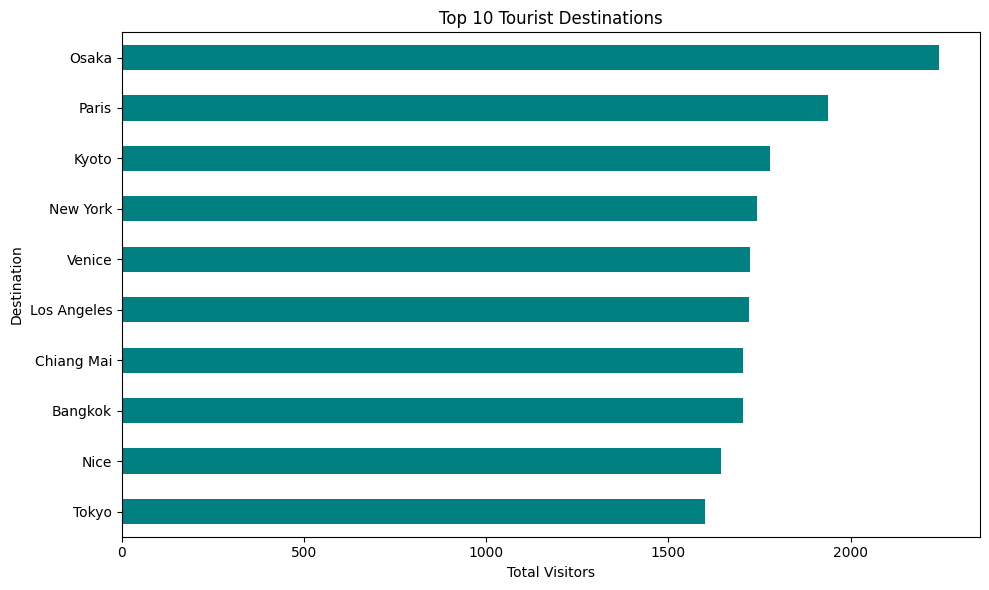

In [9]:
destination_analysis = (
    clean_df.groupby("Destination")["Visitors"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Tourist Destinations:")
display(destination_analysis.head(10).to_frame())

plt.figure(figsize=(10, 6))

destination_analysis.head(10).sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Top 10 Tourist Destinations")
plt.xlabel("Total Visitors")
plt.ylabel("Destination")

plt.tight_layout()

plt.savefig(
    "Tourism_Data_Analysis/visualizations/popular_destinations.png",
    dpi=150
)

plt.show()

MONTHLY TRAVEL TRENDS - 2025


,Total Visitors
Jan,3419
Feb,2647
Mar,2305
Apr,1999
May,2077
Jun,2868
Jul,1935
Aug,2752
Sep,2186
Oct,2664


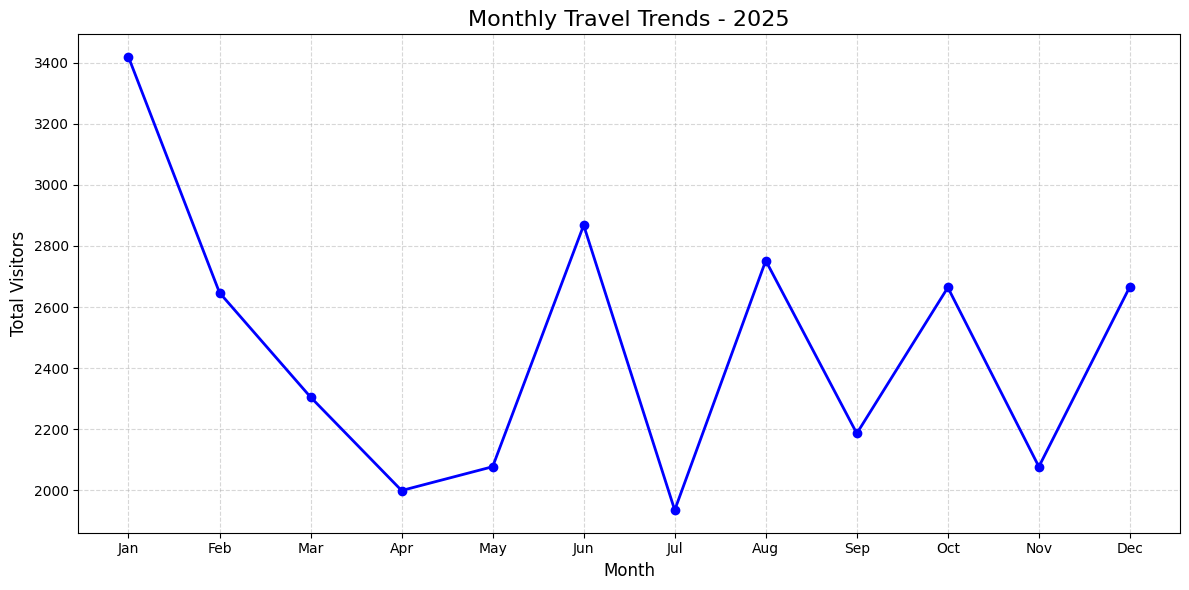

Monthly travel analysis completed successfully!


In [11]:

# Extract month from travel date
clean_df["Month"] = pd.to_datetime(
    clean_df["Travel_Date"]
).dt.month

# Calculate monthly visitors
monthly_analysis = (
    clean_df.groupby("Month")["Visitors"]
    .sum()
    .reindex(range(1, 13), fill_value=0)
)

# Month names
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_analysis.index = month_names

# Display results
print("MONTHLY TRAVEL TRENDS - 2025")
display(monthly_analysis.to_frame(name="Total Visitors"))

# Save analysis
monthly_analysis.to_csv(
    "Tourism_Data_Analysis/report/monthly_travel_analysis.csv"
)

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_analysis.index,
    monthly_analysis.values,
    marker="o",
    color="blue",
    linewidth=2
)

plt.title("Monthly Travel Trends - 2025", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Visitors", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

# Save chart
plt.savefig(
    "Tourism_Data_Analysis/visualizations/monthly_travel_trends.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Monthly travel analysis completed successfully!")



COUNTRY-WISE TOURISM ANALYSIS


,Total Visitors
Country,
Japan,5621
India,5302
France,4839
Thailand,4831
USA,4535
Italy,4468


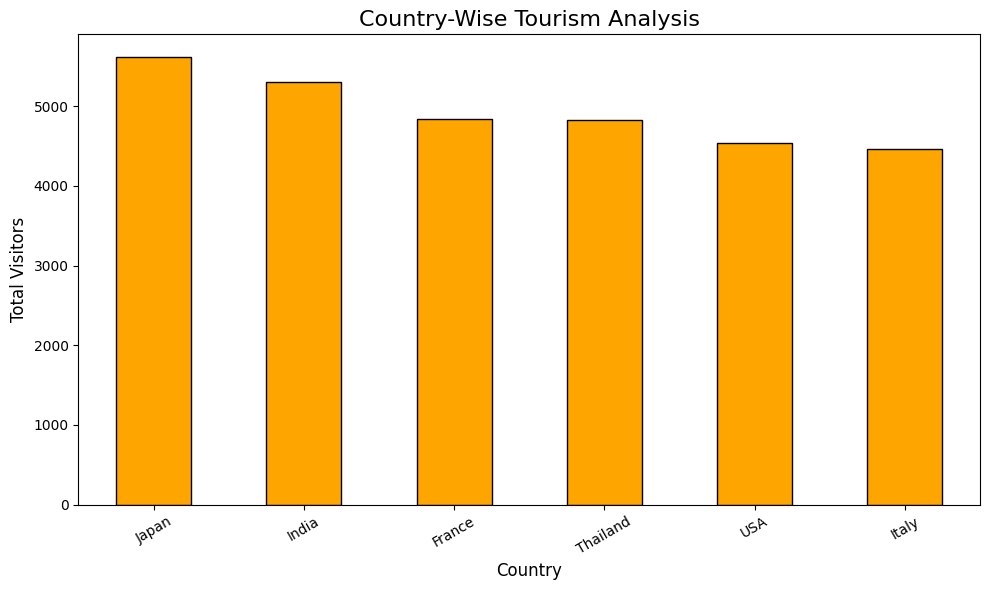

Country-wise analysis completed successfully!


In [12]:

# Calculate visitors by country
country_analysis = (
    clean_df.groupby("Country")["Visitors"]
    .sum()
    .sort_values(ascending=False)
)

# Display results
print("COUNTRY-WISE TOURISM ANALYSIS")
display(country_analysis.to_frame(name="Total Visitors"))

# Save results
country_analysis.to_csv(
    "Tourism_Data_Analysis/report/country_wise_analysis.csv"
)

# Create bar chart
plt.figure(figsize=(10, 6))

country_analysis.plot(
    kind="bar",
    color="orange",
    edgecolor="black"
)

plt.title("Country-Wise Tourism Analysis", fontsize=16)
plt.xlabel("Country", fontsize=12)
plt.ylabel("Total Visitors", fontsize=12)
plt.xticks(rotation=30)

plt.tight_layout()

# Save chart
plt.savefig(
    "Tourism_Data_Analysis/visualizations/country_wise_tourism.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Country-wise analysis completed successfully!")


TRAVEL PURPOSE ANALYSIS


,Total Visitors
Travel_Purpose,
Cultural,7859
Leisure,7783
Business,7284
Adventure,6670


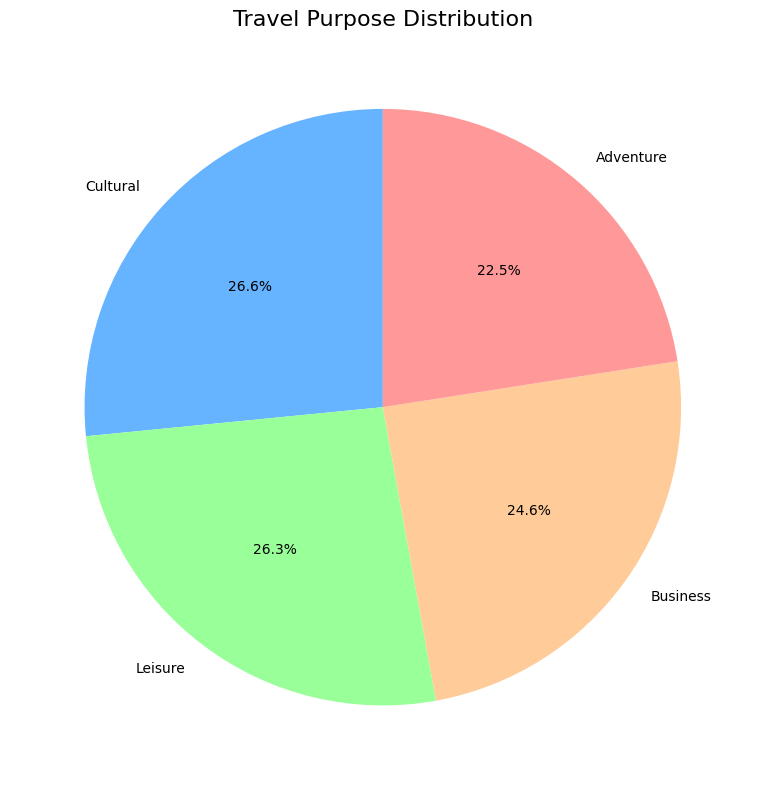

Travel purpose analysis completed successfully!


In [13]:

# Calculate visitors by travel purpose
purpose_analysis = (
    clean_df.groupby("Travel_Purpose")["Visitors"]
    .sum()
    .sort_values(ascending=False)
)

# Display results
print("TRAVEL PURPOSE ANALYSIS")
display(purpose_analysis.to_frame(name="Total Visitors"))

# Save results
purpose_analysis.to_csv(
    "Tourism_Data_Analysis/report/travel_purpose_analysis.csv"
)

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    purpose_analysis.values,
    labels=purpose_analysis.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#66b3ff", "#99ff99", "#ffcc99", "#ff9999"]
)

plt.title("Travel Purpose Distribution", fontsize=16)
plt.tight_layout()

# Save chart
plt.savefig(
    "Tourism_Data_Analysis/visualizations/travel_purpose_analysis.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Travel purpose analysis completed successfully!")



AVERAGE TRAVEL COST BY COUNTRY (USD)


,Average Cost
Country,
USA,1749.06
Italy,1639.99
India,1626.27
Japan,1598.41
Thailand,1587.06
France,1459.19


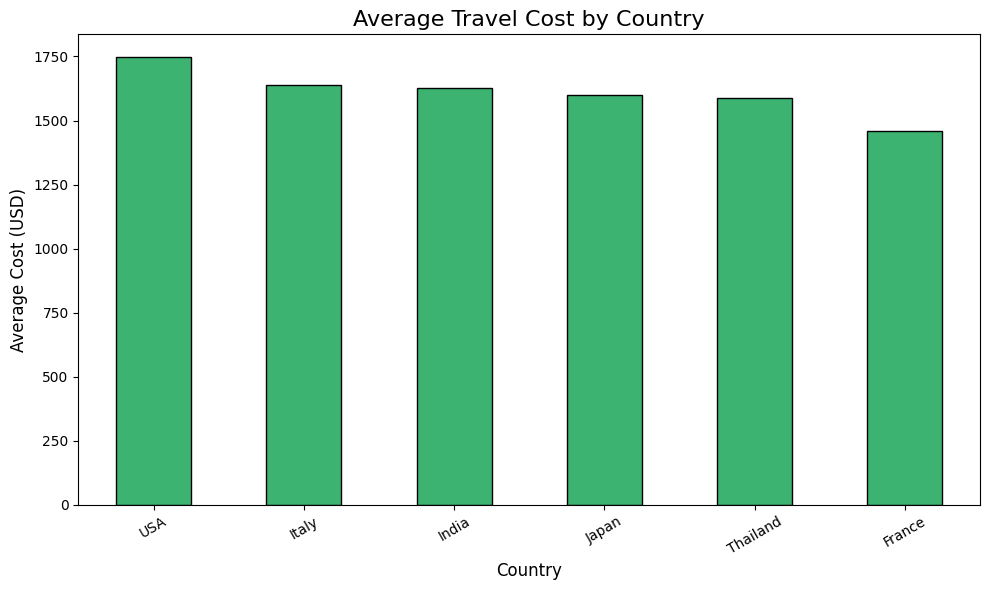

Travel cost analysis completed successfully!


In [14]:

# Calculate average travel cost
cost_analysis = (
    clean_df.groupby("Country")["Travel_Cost_USD"]
    .mean()
    .sort_values(ascending=False)
)

# Display results
print("AVERAGE TRAVEL COST BY COUNTRY (USD)")
display(cost_analysis.round(2).to_frame(name="Average Cost"))

# Save results
cost_analysis.to_csv(
    "Tourism_Data_Analysis/report/travel_cost_analysis.csv"
)

# Create bar chart
plt.figure(figsize=(10, 6))

cost_analysis.plot(
    kind="bar",
    color="mediumseagreen",
    edgecolor="black"
)

plt.title("Average Travel Cost by Country", fontsize=16)
plt.xlabel("Country", fontsize=12)
plt.ylabel("Average Cost (USD)", fontsize=12)
plt.xticks(rotation=30)

plt.tight_layout()

# Save chart
plt.savefig(
    "Tourism_Data_Analysis/visualizations/travel_cost_analysis.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Travel cost analysis completed successfully!")



In [16]:

# Calculate project summary
total_records = len(clean_df)

total_visitors = int(
    clean_df["Visitors"].sum()
)

average_duration = round(
    clean_df["Trip_Duration_Days"].mean(), 2
)

average_rating = round(
    clean_df["Rating"].mean(), 2
)

average_cost = round(
    clean_df["Travel_Cost_USD"].mean(), 2
)

top_destination = (
    clean_df.groupby("Destination")["Visitors"]
    .sum()
    .idxmax()
)

top_country = (
    clean_df.groupby("Country")["Visitors"]
    .sum()
    .idxmax()
)

top_purpose = (
    clean_df.groupby("Travel_Purpose")["Visitors"]
    .sum()
    .idxmax()
)

summary_df = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Visitors",
        "Average Trip Duration (Days)",
        "Average Tourist Rating",
        "Average Travel Cost (USD)",
        "Top Tourist Destination",
        "Top Country",
        "Most Popular Travel Purpose"
    ],
    "Result": [
        total_records,
        total_visitors,
        average_duration,
        average_rating,
        average_cost,
        top_destination,
        top_country,
        top_purpose
    ]
})

print("=" * 45)
print("TOURISM DATA ANALYSIS - FINAL SUMMARY")
print("=" * 45)

display(summary_df)

# Save summary
summary_df.to_csv(
    "Tourism_Data_Analysis/report/final_summary.csv",
    index=False
)

print("Final summary saved successfully!")



TOURISM DATA ANALYSIS - FINAL SUMMARY


,Metric,Result
0,Total Records,600
1,Total Visitors,29596
2,Average Trip Duration (Days),7.52
3,Average Tourist Rating,2.98
4,Average Travel Cost (USD),1610.0
5,Top Tourist Destination,Osaka
6,Top Country,Japan
7,Most Popular Travel Purpose,Cultural


Final summary saved successfully!


In [17]:

import os

readme_content = """
# Tourism Data Analysis and Travel Trend Visualization

## 1. Project Overview

This project analyzes tourism data and visualizes travel trends
using Python data analysis and visualization libraries.

## 2. Objectives

- Identify popular tourist destinations.
- Analyze monthly travel trends.
- Compare tourism activity across countries.
- Understand travel purposes.
- Analyze average travel costs.
- Present findings using charts and graphs.

## 3. Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab
- GitHub

## 4. Dataset Description

The dataset contains 600 sample records with the following fields:

- Travel_Date
- Country
- Destination
- Visitors
- Travel_Purpose
- Trip_Duration_Days
- Accommodation
- Travel_Cost_USD
- Rating

IMPORTANT:
This project uses a synthetically generated sample dataset.
It does not represent actual tourist records or verified tourism statistics.

## 5. Project Structure

- dataset/ : Tourism datasets
- notebook/ : Python notebook
- visualizations/ : Generated charts
- dashboard/ : Dashboard folder
- report/ : Analysis reports

## 6. Analysis Performed

1. Popular Tourist Destinations
2. Monthly Travel Trends
3. Country-Wise Tourism Analysis
4. Travel Purpose Analysis
5. Average Travel Cost Analysis
6. Final Project Summary

## 7. Visualizations

The project generates the following charts:

- popular_destinations.png
- monthly_travel_trends.png
- country_wise_tourism.png
- travel_purpose_analysis.png
- travel_cost_analysis.png

## 8. How to Run

1. Open the notebook using Google Colab.
2. Run the notebook cells from top to bottom.
3. The dataset will be generated automatically.
4. Data cleaning and analysis will be performed.
5. Charts and report files will be generated.

## 9. Conclusion

This project demonstrates how Python can be used to analyze
tourism-related sample data, identify travel patterns, and
visualize results using charts.

The findings are based on synthetic data and should not be
interpreted as real-world tourism statistics.
"""

readme_path = "Tourism_Data_Analysis/report/README.md"

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")
print("Location:", readme_path)



README.md created successfully!
Location: Tourism_Data_Analysis/report/README.md


In [18]:

import os

project_folder = "Tourism_Data_Analysis"

print("PROJECT FILES")
print("=" * 40)

for root, dirs, files in os.walk(project_folder):
    for filename in files:
        filepath = os.path.join(root, filename)
        print(filepath)

print("\nProject file check completed!")



PROJECT FILES
Tourism_Data_Analysis/dataset/tourism_data.csv
Tourism_Data_Analysis/dataset/tourism_data_cleaned.csv
Tourism_Data_Analysis/report/monthly_travel_analysis.csv
Tourism_Data_Analysis/report/travel_cost_analysis.csv
Tourism_Data_Analysis/report/travel_purpose_analysis.csv
Tourism_Data_Analysis/report/country_wise_analysis.csv
Tourism_Data_Analysis/report/final_summary.csv
Tourism_Data_Analysis/report/README.md
Tourism_Data_Analysis/visualizations/travel_cost_analysis.png
Tourism_Data_Analysis/visualizations/popular_destinations.png
Tourism_Data_Analysis/visualizations/monthly_travel_trends.png
Tourism_Data_Analysis/visualizations/travel_purpose_analysis.png
Tourism_Data_Analysis/visualizations/country_wise_tourism.png

Project file check completed!


In [20]:

import shutil
import os

zip_file = shutil.make_archive(
    "Tourism_Data_Analysis",
    "zip",
    root_dir=".",
    base_dir="Tourism_Data_Analysis"
)

print("Project ZIP created successfully!")
print("ZIP file:", zip_file)

print("File size (MB):", round(
    os.path.getsize(zip_file) / (1024 * 1024), 2
))



Project ZIP created successfully!
ZIP file: /content/Tourism_Data_Analysis.zip
File size (MB): 0.25
Project ZIP created successfully!
ZIP file: /content/Tourism_Data_Analysis.zip
File size (MB): 0.25


In [21]:

from google.colab import files

files.download("Tourism_Data_Analysis.zip")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>